# LeNet

LeNet-5 описали Ян Лекун и соавторы в 1998 году в работе о распознавании документов. Модель создавали для рукописных цифр: свёртки выделяли признаки, пулинг уменьшал карты признаков, а последние слои определяли класс. [Оригинальная статья](https://leon.bottou.org/papers/lecun-98h).

Здесь проверим, как LeNet-5 справится с цветными изображениями CIFAR-10 размером 32×32. Вместо одного канала первый свёрточный слой у нас принимает три. Оставляем три свёртки с `Tanh` и два слоя среднего пулинга, а на выходе получаем 10 чисел - логиты для каждого из классов.

Ниже показана наша адаптация LeNet.

<img src="images/lenet5.svg" alt="Схема LeNet-5" height="600">

In [1]:
import sys
from functools import partial
from pathlib import Path

import pandas as pd
import torch
import torch.nn as nn
from aim import Run
from torch.utils.data import TensorDataset
from torchvision.transforms import v2

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "utils"))

from data_utils import (
    AugmentedDataset,
    TestImagesDataset,
    calculate_mean_std,
    create_dataloader,
    images_to_tensor,
    standardize_batch,
    train_dataset_split,
)
from train_utils import train, predict_submission

## Параметры обучения

Основные параметры validation-эксперимента.

In [2]:
SEED = 52
TRAIN_FRACTION = 0.8
BATCH_SIZE = 512
NUM_WORKERS = 4

EPOCH_COUNT = 1000
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 50 # количество эпох без увеличения accuracy для остановки

In [3]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

torch.manual_seed(SEED)
print(f"Устройство: {DEVICE}")

Устройство: mps


## Работа с данными

In [4]:
# Исходные изображения храним в uint8 без деления на 255.
X_train, y_train = images_to_tensor(
    PROJECT_ROOT / "data/train",
    PROJECT_ROOT / "data/trainLabels.csv",
)
class_names = sorted(pd.read_csv(PROJECT_ROOT / "data/trainLabels.csv")["label"].unique().tolist())

Разделим размеченные данные на train и val: 80% изображений пойдут на обучение, а оставшиеся 20% на проверку после каждой эпохи.


In [5]:
ds_train = TensorDataset(X_train, y_train)

In [6]:
ds_train, ds_val = train_dataset_split(
    ds_train, train_size=TRAIN_FRACTION, random_seed=SEED,
)

### Стандартизация данных

Mean и std считаем только по train. Картинки храним в uint8, поэтому статистики тоже получаются в шкале от 0 до 255. Перед подачей в модель переводим батч в float32 и стандартизируем. Для val и test используем те же mean и std, что и при обучении выбранной модели.


In [ ]:
# Статистики считаем только по train, без картинок из val
split_mean, split_std = calculate_mean_std(ds_train)


In [ ]:
# Стандартизуем train после переноса батча на устройство
standardize_split_batch = partial(
    standardize_batch,
    mean=split_mean.to(DEVICE),
    std=split_std.to(DEVICE),
)


In [ ]:
# Val стандартизуем один раз на CPU, без аугментаций
val_x = standardize_batch(
    X_train[ds_val.indices], mean=split_mean, std=split_std,
)
ds_val_ready = TensorDataset(val_x, y_train[ds_val.indices])


### Аугментация данных

В [эксперименте с аугментациями](LeNet_Augmentation_Experiments.ipynb) лучшим оказался набор crop + horizontal flip + rotation. Переносим сюда те же настройки и порядок операций: сначала crop, затем поворот и горизонтальное отражение.

- Crop вырезает случайный участок размером 32×32 после отражающего padding на 4 пикселя.
- Rotation поворачивает изображение на случайный угол от -10° до 10°.
- Horizontal flip отражает изображение по горизонтали. 

Каждая из трёх операций применяется независимо с вероятностью 0,5.

Аугментации выполняются только для train, при каждом обращении к изображению. Val и test не аугментируем.


<img src="images/lenet_augmentation_examples.png" alt="Оригиналы и результаты crop, rotation, horizontal flip и всей комбинации" width="900">

In [8]:
rotation_fill = tuple(round(value) for value in split_mean.tolist())
train_transform = v2.Compose([
    v2.RandomApply([
        v2.RandomCrop(32, padding=4, padding_mode="reflect"),
    ], p=0.5),
    v2.RandomApply([
        v2.RandomRotation(10, interpolation=v2.InterpolationMode.BILINEAR, fill=rotation_fill),
    ], p=0.5),
    v2.RandomHorizontalFlip(p=0.5),
])
ds_train_aug = AugmentedDataset(ds_train, transform=train_transform)


In [11]:
dl_train = create_dataloader(
    ds_train_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    random_seed=SEED,
    num_workers=NUM_WORKERS,
)
dl_val = create_dataloader(
    ds_val_ready,
    batch_size=BATCH_SIZE,
    shuffle=False,
    random_seed=SEED,
)

## Создание класса LeNet

In [12]:
class LeNet5(nn.Module):
    """Упрощённая адаптация LeNet-5 для изображений CIFAR-10 размером 32x32."""

    def __init__(
        self,
        in_channels: int = 3,
        output_size: int = 10,
        image_size: tuple[int, int] = (32, 32)
    ):

        super().__init__()

        modules = []
        conv_layers = [6, 16, 120]

        in_ = in_channels # количество входных каналов для свёртки
        for i in range(len(conv_layers)): # цикл добавления свёрточных слоёв, 1 слой - (свёртка + активация + пуллинг)

            # свёртка
            modules.append(nn.Conv2d(
                in_channels=in_,
                out_channels=conv_layers[i],
                kernel_size=5,
                stride=1,
                padding=0,
            ))
            in_ = conv_layers[i]

            modules.append(nn.Tanh()) # слой активации после какждой свёртки

            if i != len(conv_layers)-1: # после каждой свёртки кроме последней добавляем слой пулинга
                modules.append(nn.AvgPool2d(kernel_size=2, stride=2))

        #вычиляем на искусственном примере размер картинки, который получился после всех свёрток
        with torch.no_grad():
            sample = torch.zeros(1, in_channels, *image_size)
            in_features = nn.Sequential(*modules)(sample).flatten(1).shape[1]

        # после всех свёрточных слоёв распрямляем значения в вектор, чтобы подать на вход линейному слою
        modules.append(nn.Flatten())

        # линейный слой на 84 нейрона
        modules.append(nn.Linear(in_features, 84))
        modules.append(nn.Tanh())

        # в конце добавляем выходной слой, дающий предсказания (логиты) для каждого из классов
        modules.append(nn.Linear(84, output_size))

        self.network = nn.Sequential(*modules)

    def forward(self, x):
        return self.network(x)

In [13]:
lenet5 = LeNet5().to(DEVICE)
loss_func = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    lenet5.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

## Обучение

Обучим модель на разделённом train, то есть `40_000` изображений и сохраним веса лучшей validation-эпохи в `MODEL_PATH`. \
В цикле обучения каждый батч train обрабатывается через `standardize_split_batch`, val уже стандартизирован. \
История записывается в Aim. \
График ноутбука отключён через `plot=False`

In [14]:
MODEL_PATH = PROJECT_ROOT / "models/lenet5.pth"

run = Run(repo=str(PROJECT_ROOT), experiment="cifar10")
run.name = "lenet-validation"

In [15]:
split_params = {
    "batch_size": BATCH_SIZE,
    "epochs": EPOCH_COUNT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "patience": PATIENCE,
    "plot": False,
    "log_every": 10,
    "architecture": type(lenet5).__name__,
    "optimizer": type(optimizer).__name__,
    "seed": SEED,
    "train_fraction": TRAIN_FRACTION,
    "num_workers": NUM_WORKERS,
    "augmentation": str(train_transform),
    "device": str(DEVICE),
    "validation": True,
}
run["hparams"] = split_params


In [16]:
try:
    train(
        lenet5, optimizer, loss_func, dl_train, dl_val,
        MODEL_PATH, DEVICE,
        EPOCH_COUNT=EPOCH_COUNT,
        patience=PATIENCE,
        plot=False,
        log_every=10,
        train_preprocess=standardize_split_batch,
        aim_run=run,
    )
    print(f"Веса модели: {MODEL_PATH}")
finally:
    run.close()

Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Ранняя остановка на эпохе 665: val_acc не улучшалась 50 эпох
Best epoch = 615, best val_acc = 0.6827
Веса модели: /Users/melikhovartem/pet_projects/CIFAR-10/models/lenet5.pth


<img src="images/lenet_val.png">

## Обучение на всех данных (без val)

Рассчитываем собственные `full_mean` и `full_std` так как train выборка изменилась (добавилось 10_000 объектов). \
Cоздаём новую модель и сохраняем веса модели на последней эпохе, в этом режиме нет выбора лучшей эпохи по validation.

In [17]:
FULL_BATCH_SIZE = 512
FULL_EPOCH_COUNT = 760
FULL_LEARNING_RATE = 3e-4
FULL_WEIGHT_DECAY = 1e-4
FULL_MODEL_PATH = PROJECT_ROOT / "models/lenet5_full.pth"


In [18]:
ds_full = TensorDataset(X_train, y_train)

In [19]:
full_mean, full_std = calculate_mean_std(ds_full)
ds_full_aug = AugmentedDataset(ds_full, transform=train_transform)

In [20]:
dl_full = create_dataloader(
    ds_full_aug,
    batch_size=FULL_BATCH_SIZE,
    shuffle=True,
    random_seed=SEED,
    num_workers=NUM_WORKERS,
)

In [21]:
# Статистики полного train не изменяют standardize_split_batch.
standardize_full_batch = partial(
    standardize_batch,
    mean=full_mean.to(DEVICE),
    std=full_std.to(DEVICE),
)

In [22]:
torch.manual_seed(SEED)
lenet_full = LeNet5().to(DEVICE)
optimizer_full = torch.optim.Adam(
    lenet_full.parameters(),
    lr=FULL_LEARNING_RATE,
    weight_decay=FULL_WEIGHT_DECAY,
)

In [23]:
full_run = Run(repo=str(PROJECT_ROOT), experiment="cifar10")
full_run.name = "lenet-full"

full_params = {
    "batch_size": FULL_BATCH_SIZE,
    "epochs": FULL_EPOCH_COUNT,
    "learning_rate": FULL_LEARNING_RATE,
    "weight_decay": FULL_WEIGHT_DECAY,
    "plot": False,
    "log_every": 10,
    "architecture": type(lenet_full).__name__,
    "optimizer": type(optimizer_full).__name__,
    "seed": SEED,
    "num_workers": NUM_WORKERS,
    "augmentation": str(train_transform),
    "device": str(DEVICE),
    "validation": False,
}
full_run["hparams"] = full_params


In [24]:
try:
    train(
        lenet_full, optimizer_full, loss_func, dl_full, None,
        FULL_MODEL_PATH, DEVICE,
        EPOCH_COUNT=FULL_EPOCH_COUNT,
        plot=False,
        log_every=10,
        train_preprocess=standardize_full_batch,
        aim_run=full_run,
    )
    print(f"Веса модели: {FULL_MODEL_PATH}")
finally:
    full_run.close()

Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Обучение завершено: 760 эпох, train_acc = 0.7351
Веса модели: /Users/melikhovartem/pet_projects/CIFAR-10/models/lenet5_full.pth


<img src="images/lenet_full.png">

## Тестирование

Загружаем только веса лучшей validation-модели из `MODEL_PATH`. Для предсказаний используем ту же стандартизацию `standardize_split_batch` и тот же порядок классов, что и при обучении. Тестовые изображения читаем в порядке `sampleSubmission.csv`, без аугментаций; результат сохраняем по пути `SUBMISSION_PATH`.

Для модели полного обучения можно включить `USE_FULL_MODEL_FOR_TEST` в первой ячейке этого раздела. Тогда выбираются веса `models/lenet5_full.pth` и отдельная стандартизация `standardize_full_batch`.


In [25]:
USE_FULL_MODEL_FOR_TEST = True

if USE_FULL_MODEL_FOR_TEST:
    test_model_weights = PROJECT_ROOT / "models/lenet5_full.pth"
    standardize_test_batch = standardize_full_batch
else:
    test_model_weights = PROJECT_ROOT / "models/lenet5.pth"
    standardize_test_batch = standardize_split_batch

In [26]:
lenet_best = LeNet5().to(DEVICE)
lenet_best.load_state_dict(torch.load(test_model_weights, map_location=DEVICE, weights_only=True))
lenet_best.eval()

LeNet5(
  (network): Sequential(
    (0): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
    (7): Tanh()
    (8): Flatten(start_dim=1, end_dim=-1)
    (9): Linear(in_features=120, out_features=84, bias=True)
    (10): Tanh()
    (11): Linear(in_features=84, out_features=10, bias=True)
  )
)

In [27]:
SAMPLE_SUBMISSION_PATH = PROJECT_ROOT / "data/sampleSubmission.csv"
ds_test = TestImagesDataset(PROJECT_ROOT / "data/test", SAMPLE_SUBMISSION_PATH)

In [28]:
dl_test = create_dataloader(
    ds_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

In [29]:
SUBMISSION_PATH = PROJECT_ROOT / "submissions/lenet_submission.csv"

submission = predict_submission(
    lenet_best, dl_test, class_names,
    SAMPLE_SUBMISSION_PATH, SUBMISSION_PATH, DEVICE,
    preprocess=standardize_test_batch,
)

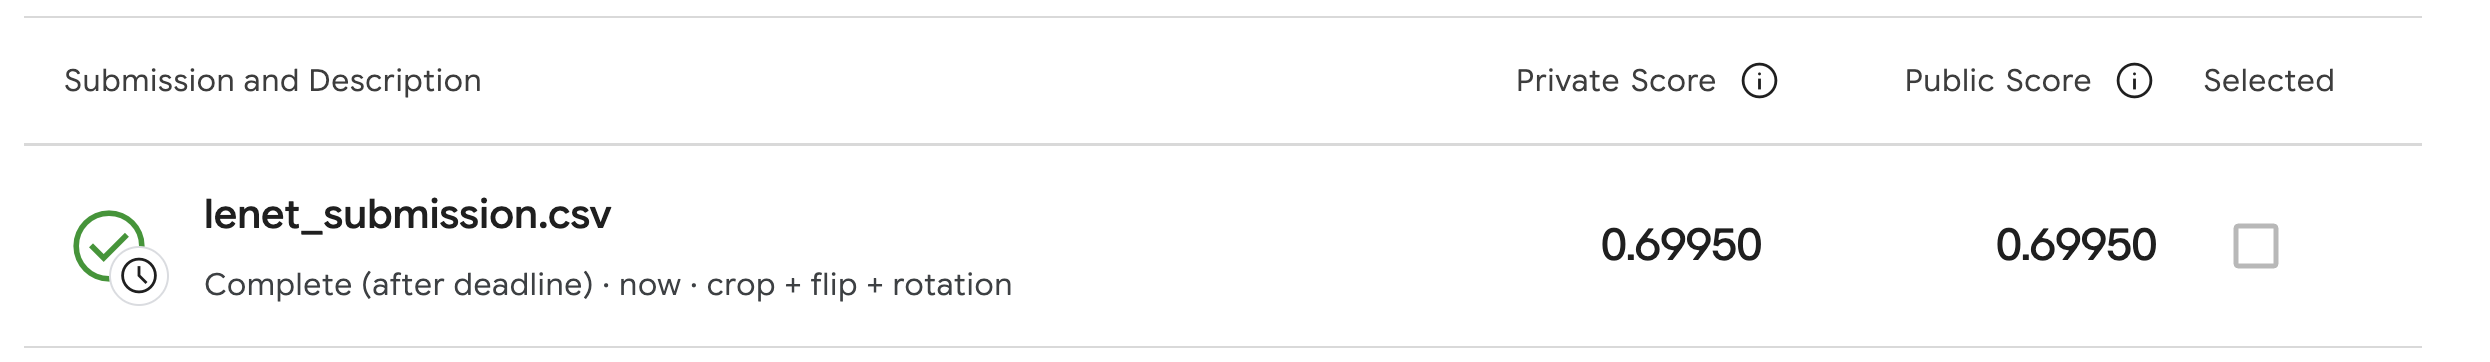
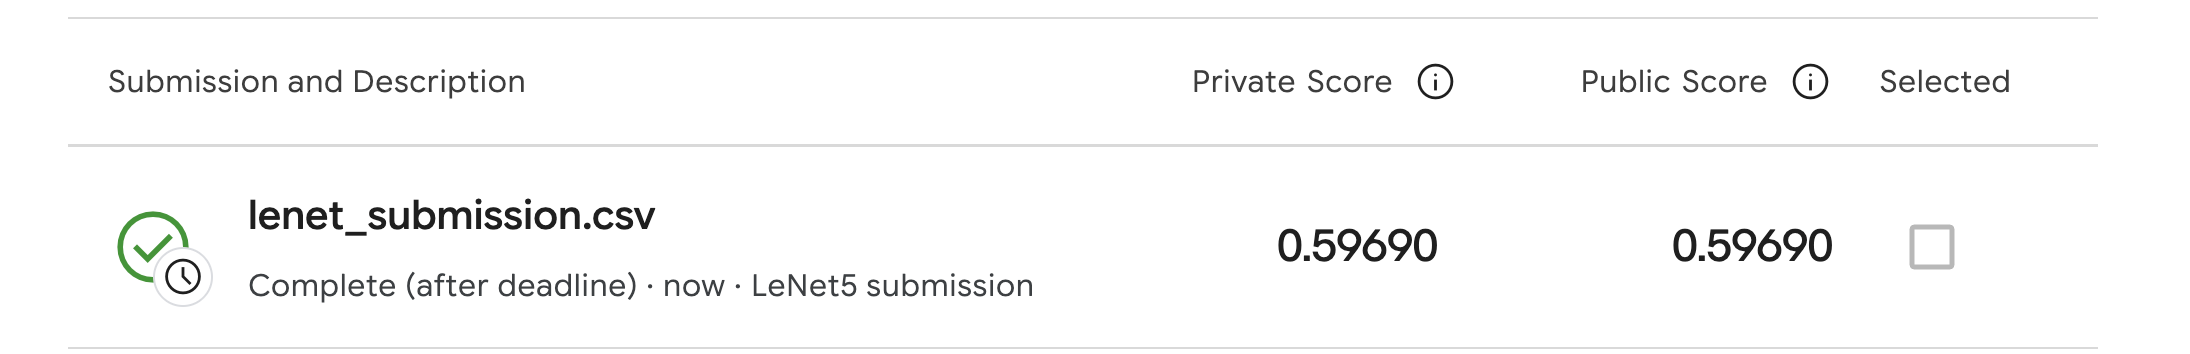

## Итог

LeNet-5 адаптирована для цветных изображений CIFAR-10 размером 32×32. При обучении используются поканальная стандартизация и аугментации **crop + horizontal flip + rotation**, выбранные по результатам [отдельного эксперимента](LeNet_Augmentation_Experiments.ipynb).

Финальная модель обучалась на всех **50 000 изображениях train в течение 760 эпох**. Для предсказаний использованы веса последней эпохи.

Итоговый файл предсказаний получил **69,95% accuracy на Kaggle**.
